# 03: Test set. Does pruning hurt human-ambiguous images more?
This notebook answers the main question (PLAN.md: Research question): *when pruned, do ResNet-18 and
DeiT-Tiny lose accuracy disproportionately on the CIFAR-10 test images that humans find ambiguous,
and does the gap differ between them?*

It is the only notebook that opens the test set and CIFAR-10H (Rule 7). It evaluates the models
saved by notebooks 01 and 02 and changes nothing about them. What is measured was fixed in PLAN.md
(Predictions, Specifications). The few analysis rules PLAN.md left open are marked **Analysis rule**
below. The assistant wrote them on 2026-10-25, before this notebook was first run on the real models.

# Setup

In [1]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

import data
import models
import pruning
import sweep
import train

In [2]:
QUICK_TEST = False  # True: use the quick-test checkpoints of notebooks 01 and 02, to check that this notebook runs.

ARCHS = ["cnn", "vit"]
METHODS = ["magnitude", "random"]
SPARSITIES = [0.3, 0.5, 0.7, 0.9, 0.95]
IMG_SIZE = 224
N_BOOT = 2000  # bootstrap resamples for the 95% intervals
SEED = 0

CKPT = {arch: Path(f"checkpoints/{arch}-quick-test" if QUICK_TEST else f"checkpoints/{arch}") for arch in ARCHS}
OUT = Path("results-quick-test" if QUICK_TEST else "results")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

COLORS = {"cnn": "#2a78d6", "vit": "#eb6834"}  # categorical blue and orange, checked for colour-blind readers
INK, GRAY, LIGHT = "#3d3d3a", "#8a8a85", "#c3c2b7"
WHEN = {"finetuned": "after the 1-epoch fine-tune", "pruned": "right after pruning"}
plt.rcParams.update({
    "font.size": 8, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e6e6", "axes.axisbelow": True, "savefig.bbox": "tight", "savefig.dpi": 200,
})

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
summary = {}  # the numbers the paper uses, saved at the end

# Human agreement
An image's *human agreement* is the share of CIFAR-10H annotators who chose its CIFAR-10 label.
**Ambiguous** = agreement ≤ 86.8%: the bottom ~10%, ties included (PLAN.md: Data). **Clear** = the rest.

In [3]:
test = data.test_set()
labels = np.array(test.targets)
counts = data.human_counts()
agreement = data.human_agreement(labels)
ambiguous = agreement <= data.AMBIGUOUS_MAX_AGREEMENT
clear = ~ambiguous
n_amb, n_clear = int(ambiguous.sum()), int(clear.sum())
assert n_amb == 1011, n_amb  # PLAN.md: Data

per_image = counts.sum(1)
print(f"annotators per image: {per_image.min()}-{per_image.max()} (median {np.median(per_image):.0f})")
print(f"ambiguous: {n_amb:,} images, clear: {n_clear:,}")
print(f"agreement = 100%: {np.mean(agreement == 1):.0%} of images; below 90%: {np.mean(agreement < 0.9):.0%}; "
      f"below 80%: {np.mean(agreement < 0.8):.0%}; below 50%: {np.mean(agreement < 0.5):.1%}")
print(f"images where most annotators chose another class than the CIFAR-10 label: {np.sum(counts.argmax(1) != labels)}")
print(f"mean agreement: ambiguous {agreement[ambiguous].mean():.1%}, clear {agreement[clear].mean():.1%}")
print("\nambiguous images per class (of 1,000 each):")
amb_per_class = {name: int(np.sum(ambiguous & (labels == c))) for c, name in enumerate(test.classes)}
for name, n in sorted(amb_per_class.items(), key=lambda kv: -kv[1]):
    print(f"  {name:>10}: {n:>4}")
summary["data"] = {"n_ambiguous": n_amb, "n_clear": n_clear, "ambiguous_per_class": amb_per_class,
                   "share_agreement_100": float(np.mean(agreement == 1)),
                   "mean_agreement_ambiguous": float(agreement[ambiguous].mean()),
                   "mean_agreement_clear": float(agreement[clear].mean())}

annotators per image: 47-63 (median 51)
ambiguous: 1,011 images, clear: 8,989
agreement = 100%: 44% of images; below 90%: 12%; below 80%: 6%; below 50%: 1.2%
images where most annotators chose another class than the CIFAR-10 label: 79
mean agreement: ambiguous 71.0%, clear 98.0%

ambiguous images per class (of 1,000 each):
        deer:  213
         cat:  208
        bird:  119
         dog:  112
        frog:   92
    airplane:   89
       truck:   62
  automobile:   50
       horse:   36
        ship:   30


## Figure 1: the agreement distribution and examples
Left: human agreement over the 10,000 test images (log scale), with the cut at 86.8%. Right: six
random ambiguous and six random clear images, titled with the CIFAR-10 label and its share of human
votes, and for ambiguous images the most popular other class.

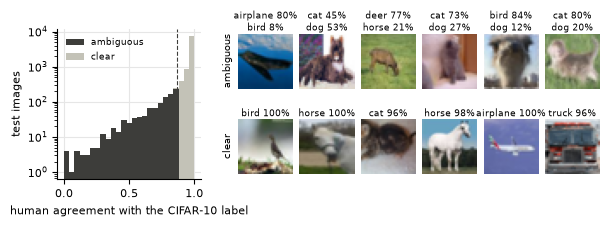

In [4]:
rng = np.random.default_rng(SEED)
examples = {"ambiguous": rng.choice(np.flatnonzero(ambiguous), 6, replace=False),
            "clear": rng.choice(np.flatnonzero(clear), 6, replace=False)}
share = counts / counts.sum(1, keepdims=True)

fig = plt.figure(figsize=(7, 1.95))
grid = fig.add_gridspec(2, 8, width_ratios=[2.6, 0.45] + [1] * 6, wspace=0.1, hspace=0.32)
ax = fig.add_subplot(grid[:, 0])
bins = np.linspace(0, 1, 26)
ax.hist([agreement[ambiguous], agreement[clear]], bins=bins, stacked=True, color=[INK, LIGHT],
        label=["ambiguous", "clear"])
ax.axvline(data.AMBIGUOUS_MAX_AGREEMENT, color=INK, lw=0.8, ls="--")
ax.set_yscale("log")
ax.set_xlabel("human agreement with the CIFAR-10 label")
ax.set_ylabel("test images")
ax.legend(frameon=False, loc="upper left", fontsize=6.5)
for row, group in enumerate(examples):
    for col, i in enumerate(examples[group]):
        a = fig.add_subplot(grid[row, 2 + col])
        a.imshow(test.data[i])
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
        a.spines[:].set_visible(False)
        title = f"{test.classes[labels[i]]} {share[i, labels[i]]:.0%}"
        if group == "ambiguous":
            other = max((c for c in range(10) if c != labels[i]), key=lambda c: counts[i, c])
            title += f"\n{test.classes[other]} {share[i, other]:.0%}"
        a.set_title(title, fontsize=6.5, pad=2)
        if col == 0:
            a.set_ylabel(group, fontsize=7.5)
fig.savefig(FIG / "fig1_data.pdf")
fig.savefig(FIG / "fig1_data.png")
plt.show()

# Test-set predictions
Every saved model is evaluated once on the 10,000 test images: per architecture, the base model, and
for every condition the model right after pruning and after the 1-epoch fine-tune. The predicted
classes are saved to `results/test_predictions.npz`, so running the notebook again does not
recompute them. The sparsity printed for each model is measured on the loaded weights, a check that
the saved models are pruned as intended.

In [5]:
CONDITIONS = [("none", 0.0)] + [(m, s) for m in METHODS for s in SPARSITIES]


def checkpoint_names():
    """'base', then '<condition>_pruned' (pruned conditions only) and '<condition>_finetuned'."""
    names = ["base"]
    for method, amount in CONDITIONS:
        name = sweep.condition_name(method, amount)
        names += [f"{name}_pruned", f"{name}_finetuned"] if method != "none" else [f"{name}_finetuned"]
    return names


pred_path = OUT / "test_predictions.npz"
preds = dict(np.load(pred_path)) if pred_path.exists() else {}
test_loader = data.loader(test, batch_size=256)
for arch in ARCHS:
    for name in checkpoint_names():
        key = f"{arch}.{name}"
        if key in preds:
            continue
        model = models.new_model(arch, pretrained=False, device=device)
        model.load_state_dict(torch.load(CKPT[arch] / f"{name}.pt", map_location=device))
        preds[key] = train.predict(model, test_loader, device, IMG_SIZE).astype(np.int8)
        print(f"{key:>26}: sparsity {pruning.sparsity(model, models.SKIP[arch]):.4f}, "
              f"test accuracy {np.mean(preds[key] == labels):.2%}")
np.savez_compressed(pred_path, **preds)
correct = {key: p == labels for key, p in preds.items()}
print(f"{len(correct)} models evaluated on {len(labels):,} test images")

44 models evaluated on 10,000 test images


# Drops on ambiguous and clear images
- **Drop** (Δ): accuracy lost, in percentage points (PLAN.md: Predictions), relative to a reference.
  Positive = accuracy lost. After the fine-tune the reference is the unpruned model with the same
  extra epoch (`none_0_finetuned`). Right after pruning it is the base model.
- **Gap** = Δ ambiguous − Δ clear. **Ratio** = Δ ambiguous ÷ Δ clear (PLAN.md: Predictions). The null
  hypothesis of uniform degradation is gap = 0, ratio = 1.
- **Analysis rule:** the ratio is shown only where Δ clear ≥ 1 point, because dividing by a drop near
  zero gives meaningless numbers.
- **Analysis rule:** 95% intervals come from a bootstrap over test images: 2,000 resamples, drawn
  separately within the ambiguous and the clear group, and the same resamples for every model, so
  comparisons between models stay paired. They cover test-set sampling noise only. With one
  training seed per condition (Rule 8, amended), run-to-run training noise is not in them.

In [6]:
keys = sorted(correct)
row = {key: i for i, key in enumerate(keys)}
M = np.stack([correct[k] for k in keys]).astype(np.float32)  # models x images, 1 = correct
rng = np.random.default_rng(SEED)


def resampled_accuracy(idx):
    """Accuracy of every model on images `idx`: column 0 on the images themselves, then one column
    per bootstrap resample. A resample is stored as how often each image was drawn."""
    n = len(idx)
    draws = rng.multinomial(n, np.full(n, 1 / n), size=N_BOOT).astype(np.float32)
    return np.concatenate([M[:, idx].mean(1, keepdims=True), M[:, idx] @ draws.T / n], axis=1)


acc_amb = resampled_accuracy(np.flatnonzero(ambiguous))
acc_clear = resampled_accuracy(np.flatnonzero(clear))
acc_all = (n_amb * acc_amb + n_clear * acc_clear) / (n_amb + n_clear)


def ci(x):
    """Point estimate and 95% percentile interval of a statistic computed on every column."""
    return float(x[0]), float(np.percentile(x[1:], 2.5)), float(np.percentile(x[1:], 97.5))


def fmt(x, digits=1):
    v, lo, hi = ci(x)
    return f"{v:+.{digits}f} [{lo:+.{digits}f}, {hi:+.{digits}f}]"


def key(arch, method, amount, when):
    """The saved model for a condition. ('none', 0.0) is the reference for `when`."""
    if method == "none":
        return f"{arch}.base" if when == "pruned" else f"{arch}.none_0_finetuned"
    return f"{arch}.{sweep.condition_name(method, amount)}_{when}"


def drops(arch, method, amount, when):
    """Accuracy lost, in percentage points, on ambiguous, clear and all images (every column)."""
    i, j = row[key(arch, method, amount, when)], row[key(arch, "none", 0.0, when)]
    return {g: 100 * (acc[j] - acc[i]) for g, acc in [("amb", acc_amb), ("clear", acc_clear), ("all", acc_all)]}

In [7]:
table = []
for when in WHEN:
    ref = "unpruned + the same extra epoch" if when == "finetuned" else "the base model"
    print(f"\n=== {WHEN[when]} (reference: {ref}) ===")
    print(f"{'model':>9} {'method':>9} {'spars.':>6} | {'acc all':>7} {'amb':>6} {'clear':>6} | "
          f"{'Δ all':>6} {'Δ amb [95% CI]':>21} {'Δ clear [95% CI]':>21} {'gap [95% CI]':>21} {'ratio [95% CI]':>21}")
    for arch in ARCHS:
        for method, amount in CONDITIONS:
            i = row[key(arch, method, amount, when)]
            d = drops(arch, method, amount, when)
            gap = d["amb"] - d["clear"]
            show_ratio = d["clear"][0] >= 1
            with np.errstate(divide="ignore", invalid="ignore"):
                ratio = d["amb"] / d["clear"]
            print(f"{models.DISPLAY[arch]:>9} {method:>9} {amount:>6.0%} | {100 * acc_all[i, 0]:>7.2f} "
                  f"{100 * acc_amb[i, 0]:>6.2f} {100 * acc_clear[i, 0]:>6.2f} | {d['all'][0]:>+6.2f} "
                  f"{fmt(d['amb']):>21} {fmt(d['clear']):>21} {fmt(gap):>21} "
                  f"{fmt(ratio, 2) if show_ratio else '-':>21}")
            table.append({
                "model": models.DISPLAY[arch], "when": when, "method": method, "sparsity": amount,
                "acc_all": 100 * float(acc_all[i, 0]), "acc_amb": 100 * float(acc_amb[i, 0]),
                "acc_clear": 100 * float(acc_clear[i, 0]),
                **{f"drop_{g}{s}": v for g in ["amb", "clear", "all"] for s, v in zip(["", "_lo", "_hi"], ci(d[g]))},
                **{f"gap{s}": v for s, v in zip(["", "_lo", "_hi"], ci(gap))},
                **{f"ratio{s}": (v if show_ratio else None) for s, v in zip(["", "_lo", "_hi"], ci(ratio))},
            })

with open(OUT / "drops.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=table[0].keys())
    writer.writeheader()
    writer.writerows(table)
summary["table"] = table


=== after the 1-epoch fine-tune (reference: unpruned + the same extra epoch) ===
    model    method spars. | acc all    amb  clear |  Δ all        Δ amb [95% CI]      Δ clear [95% CI]          gap [95% CI]        ratio [95% CI]
ResNet-18      none     0% |   94.98  78.54  96.83 |  +0.00     +0.0 [+0.0, +0.0]     +0.0 [+0.0, +0.0]     +0.0 [+0.0, +0.0]                     -
ResNet-18 magnitude    30% |   94.90  78.64  96.73 |  +0.08     -0.1 [-1.4, +1.2]     +0.1 [-0.1, +0.3]     -0.2 [-1.5, +1.1]                     -
ResNet-18 magnitude    50% |   94.88  77.74  96.81 |  +0.10     +0.8 [-0.6, +2.3]     +0.0 [-0.2, +0.2]     +0.8 [-0.6, +2.3]                     -
ResNet-18 magnitude    70% |   94.49  76.85  96.47 |  +0.49     +1.7 [-0.2, +3.5]     +0.4 [+0.1, +0.6]     +1.3 [-0.6, +3.2]                     -
ResNet-18 magnitude    90% |   91.18  68.84  93.69 |  +3.80    +9.7 [+7.0, +12.3]     +3.1 [+2.7, +3.6]     +6.6 [+3.8, +9.2]  +3.09 [+2.17, +4.14]
ResNet-18 magnitude    95% |  

.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4609: RuntimeWarning: invalid value encountered in scalar subtract
  diff_b_a = b - a


## The ratio at a matched overall drop
**Analysis rule:** *D\** is the largest overall drop that all four curves (2 models × 2 methods) reach,
that is, the smallest of their maximum drops. Each curve is interpolated linearly between neighbouring
sparsity levels, walking down from 95% to the first segment that reaches D\*, and the ratio is Δ
ambiguous ÷ Δ clear there. The interpolation weight comes from the point estimates and is reused
in every bootstrap resample. Computed separately after the fine-tune (main) and right after pruning.

In [8]:
def at_drop(arch, method, when, target):
    """The drops (every column) where this curve's overall drop equals `target`, and the sparsity there."""
    levels = [("none", 0.0)] + [(method, s) for s in SPARSITIES]
    d = [drops(arch, m, s, when) for m, s in levels]
    x = [p["all"][0] for p in d]
    for i in reversed(range(len(d) - 1)):
        lo, hi = x[i], x[i + 1]
        if min(lo, hi) <= target <= max(lo, hi):
            w = 0.0 if hi == lo else (target - lo) / (hi - lo)
            return {g: (1 - w) * d[i][g] + w * d[i + 1][g] for g in d[i]}, (1 - w) * levels[i][1] + w * levels[i + 1][1]
    raise ValueError(f"{arch} {method} never reaches an overall drop of {target}")


matched = {}
summary["matched"] = {}
for when in WHEN:
    curves = [(a, m) for a in ARCHS for m in METHODS]
    d_star = min(max(drops(a, m, s, when)["all"][0] for s in SPARSITIES) for a, m in curves)
    print(f"\n=== {WHEN[when]}: matched overall drop D* = {d_star:.2f} points ===")
    summary["matched"][when] = {"d_star": float(d_star)}
    for a, m in curves:
        d, s = at_drop(a, m, when, d_star)
        ratio, gap = d["amb"] / d["clear"], d["amb"] - d["clear"]
        matched[when, a, m] = {"ratio": ratio, "gap": gap}
        summary["matched"][when][f"{a}_{m}"] = {"sparsity": float(s), "drop_amb": ci(d["amb"]), "drop_clear": ci(d["clear"]),
                                               "gap": ci(gap), "ratio": ci(ratio)}
        print(f"{models.DISPLAY[a]:>9} {m:>9} (at {s:.0%} sparsity): Δ amb {fmt(d['amb'])}, Δ clear {fmt(d['clear'])}, "
              f"gap {fmt(gap)}, ratio {fmt(ratio, 2)}")


=== after the 1-epoch fine-tune: matched overall drop D* = 12.13 points ===
ResNet-18 magnitude (at 95% sparsity): Δ amb +19.0 [+15.9, +22.1], Δ clear +11.4 [+10.6, +12.1], gap +7.6 [+4.4, +10.8], ratio +1.67 [+1.38, +1.97]
ResNet-18    random (at 55% sparsity): Δ amb +18.0 [+15.4, +20.6], Δ clear +11.5 [+10.9, +12.0], gap +6.5 [+3.8, +9.2], ratio +1.57 [+1.34, +1.82]
DeiT-Tiny magnitude (at 70% sparsity): Δ amb +21.1 [+18.1, +24.2], Δ clear +11.1 [+10.4, +11.8], gap +10.0 [+6.9, +13.2], ratio +1.90 [+1.61, +2.21]
DeiT-Tiny    random (at 19% sparsity): Δ amb +17.7 [+15.6, +19.7], Δ clear +11.5 [+11.0, +12.1], gap +6.2 [+4.0, +8.3], ratio +1.54 [+1.34, +1.73]

=== right after pruning: matched overall drop D* = 84.61 points ===
ResNet-18 magnitude (at 90% sparsity): Δ amb +56.8 [+53.1, +60.4], Δ clear +87.7 [+87.0, +88.4], gap -31.0 [-34.7, -27.2], ratio +0.65 [+0.61, +0.69]
ResNet-18    random (at 30% sparsity): Δ amb +56.5 [+52.8, +60.2], Δ clear +87.8 [+87.0, +88.5], gap -31.2 [-35.0

## Figure 2: the gap against the overall drop (main result)
PLAN.md (Pruning): *for each model we sweep sparsity and plot the ambiguous-vs-clear gap against the
overall accuracy drop*, so the two architectures are compared at matched overall accuracy loss, not
at matched sparsity. Each line runs from the unpruned reference (0, 0) through 30, 50, 70, 90 and 95%
sparsity. Bars are 95% intervals. Black line: no gap (the null hypothesis). Gray lines: the gap that
the predicted ratios (2 for the CNN, 1.5 for the ViT) would produce. Thin vertical line: D\*.

*Added after seeing the results:* thin coloured lines show the chance floor that PLAN.md warned about,
the gap if both groups lost the same *share* of their accuracy above chance (10%). Ambiguous images
start lower, so they have less room to fall, and as a model approaches chance the gap must turn
negative. Left: after the 1-epoch fine-tune (the main result). Right: right after pruning, before any
recovery.

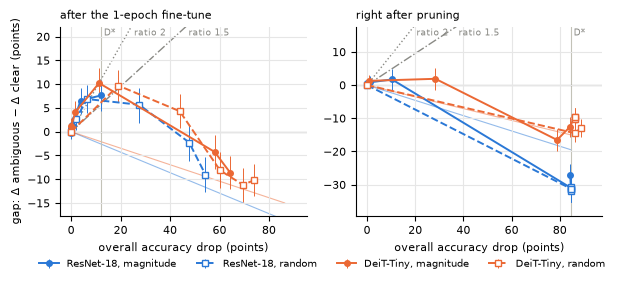

In [9]:
frac_amb = n_amb / (n_amb + n_clear)


def gap_for_ratio(ratio, overall_drop):
    """The gap a constant ratio produces: overall = f*amb + (1-f)*clear, and amb = ratio * clear."""
    return (ratio - 1) * overall_drop / (frac_amb * ratio + 1 - frac_amb)


def plot_gap(ax, when):
    ys = []
    for arch in ARCHS:
        ref = row[key(arch, 'none', 0.0, when)]
        a_amb, a_clear, a_all = (100 * acc[ref, 0] for acc in (acc_amb, acc_clear, acc_all))
        floor_x = np.array([0, a_all - 10])  # same share of above-chance accuracy lost by both groups
        ax.plot(floor_x, floor_x * (a_amb - a_clear) / (a_all - 10), color=COLORS[arch], lw=0.8, alpha=0.5, zorder=0)
        for method in METHODS:
            pts = [drops(arch, "none", 0.0, when)] + [drops(arch, method, s, when) for s in SPARSITIES]
            x = [p["all"][0] for p in pts]
            gaps = np.array([ci(p["amb"] - p["clear"]) for p in pts])
            ys += list(gaps[:, 1]) + list(gaps[:, 2])
            filled = method == "magnitude"
            ax.errorbar(x, gaps[:, 0], yerr=[gaps[:, 0] - gaps[:, 1], gaps[:, 2] - gaps[:, 0]],
                        color=COLORS[arch], ls="-" if filled else "--", marker="o" if filled else "s",
                        mfc=COLORS[arch] if filled else "white", ms=4, lw=1.4, elinewidth=0.7,
                        label=f"{models.DISPLAY[arch]}, {method}")
    lo, hi = min(ys), max(ys)
    ax.set_ylim(lo - 0.1 * (hi - lo), hi + 0.3 * (hi - lo))
    top = ax.get_ylim()[1]
    xs = np.linspace(0, ax.get_xlim()[1], 400)
    for ratio, ls in [(2, ":"), (1.5, "-.")]:
        g = gap_for_ratio(ratio, xs)
        ax.plot(xs, g, color=GRAY, ls=ls, lw=1, zorder=0)
        exit_x = xs[np.argmax(g >= top)] if (g >= top).any() else xs[-1]
        ax.annotate(f"ratio {ratio:g}", (exit_x, min(g.max(), top)), fontsize=6.5, color=GRAY,
                    ha="left", va="top", xytext=(2, -1), textcoords="offset points")
    d_star = summary["matched"][when]["d_star"]
    ax.axvline(d_star, color=LIGHT, lw=0.8, zorder=0)
    ax.annotate("D*", (d_star, top), fontsize=6.5, color=GRAY, ha="left", va="top",
                xytext=(2, -1), textcoords="offset points")
    ax.axhline(0, color=INK, lw=0.8, zorder=0)
    ax.set_xlabel("overall accuracy drop (points)")
    ax.set_title(WHEN[when], loc="left", fontsize=8)


fig, axes = plt.subplots(1, 2, figsize=(7, 2.45))
for ax, when in zip(axes, WHEN):
    plot_gap(ax, when)
axes[0].set_ylabel("gap: Δ ambiguous − Δ clear (points)")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.03), ncol=4, fontsize=7)
fig.savefig(FIG / "fig2_gap.pdf")
fig.savefig(FIG / "fig2_gap.png")
plt.show()

# The predictions, checked
PLAN.md (Predictions), checked after the fine-tune at D\* (main), and right after pruning for
comparison.

**Analysis rule (verdicts):**
- **Null hypothesis** (uniform degradation): rejected for a model and method if the 95% interval of
  its gap at D\* excludes 0.
- **Predictions 1 and 2:** supported if the predicted ratio (2 for ResNet-18, 1.5 for DeiT-Tiny,
  magnitude pruning) lies inside the 95% interval of the ratio at D\*.
- **Prediction 3:** supported if, at every pruned sparsity and in both models, random pruning's overall
  drop exceeds magnitude pruning's with the 95% interval of the difference above 0.
- **Prediction 4:** supported if, at D\*, random pruning's ratio is closer to 1 than magnitude
  pruning's in both models (point estimates), and the ViT's random-pruning ratio is below the
  CNN's. The intervals of these differences are shown alongside.

In [10]:
def verdict(ok):
    return "SUPPORTED" if ok else "not supported"


summary["verdicts"] = {}
for when in WHEN:
    m = matched
    print(f"\n=== {WHEN[when]} ===")
    print("Null hypothesis (gap = 0 at D*):")
    for a in ARCHS:
        for meth in METHODS:
            v, lo, hi = ci(m[when, a, meth]["gap"])
            print(f"  {models.DISPLAY[a]:>9} {meth:>9}: gap {v:+.2f} [{lo:+.2f}, {hi:+.2f}] -> "
                  f"{'rejected' if lo > 0 or hi < 0 else 'not rejected'}")

    r = {(a, meth): m[when, a, meth]["ratio"] for a in ARCHS for meth in METHODS}
    v1 = ci(r["cnn", "magnitude"])
    v2 = ci(r["vit", "magnitude"])
    p1, p2 = v1[1] <= 2 <= v1[2], v2[1] <= 1.5 <= v2[2]
    print(f"1. ResNet-18, magnitude, ratio ~ 2:   {v1[0]:.2f} [{v1[1]:.2f}, {v1[2]:.2f}] -> {verdict(p1)}")
    print(f"2. DeiT-Tiny, magnitude, ratio ~ 1.5: {v2[0]:.2f} [{v2[1]:.2f}, {v2[2]:.2f}] -> {verdict(p2)}")
    diff = ci(r["cnn", "magnitude"] - r["vit", "magnitude"])
    print(f"   ratio ResNet-18 - DeiT-Tiny (magnitude): {diff[0]:+.2f} [{diff[1]:+.2f}, {diff[2]:+.2f}]")

    p3 = True
    print("3. random loses more overall accuracy than magnitude at the same sparsity (Δ random - Δ magnitude):")
    for a in ARCHS:
        cells = [ci(drops(a, "random", s, when)["all"] - drops(a, "magnitude", s, when)["all"]) for s in SPARSITIES]
        p3 &= all(lo > 0 for _, lo, _ in cells)
        print(f"   {models.DISPLAY[a]:>9}: " + ", ".join(f"{s:.0%}: {v:+.1f} [{lo:+.1f}, {hi:+.1f}]" for s, (v, lo, hi) in zip(SPARSITIES, cells)))
    print(f"   -> {verdict(p3)}")

    closer = {a: np.abs(r[a, "magnitude"] - 1) - np.abs(r[a, "random"] - 1) for a in ARCHS}  # > 0: random closer to 1
    p4 = all(closer[a][0] > 0 for a in ARCHS) and r["vit", "random"][0] < r["cnn", "random"][0]
    print("4. random narrows the gap for both, and the ViT's ratio stays below the CNN's:")
    for a in ARCHS:
        print(f"   {models.DISPLAY[a]:>9}: ratio magnitude {r[a, 'magnitude'][0]:.2f}, random {r[a, 'random'][0]:.2f}; "
              f"|mag - 1| - |random - 1| = {fmt(closer[a], 2)}")
    print(f"   random-pruning ratio DeiT-Tiny - ResNet-18: {fmt(r['vit', 'random'] - r['cnn', 'random'], 2)}")
    print(f"   -> {verdict(p4)}")
    summary["verdicts"][when] = {"p1": bool(p1), "p2": bool(p2), "p3": bool(p3), "p4": bool(p4),
                                "ratio_diff_cnn_minus_vit_magnitude": diff,
                                "ratio_diff_vit_minus_cnn_random": ci(r["vit", "random"] - r["cnn", "random"]),
                                "closer_to_1": {a: ci(closer[a]) for a in ARCHS}}


=== after the 1-epoch fine-tune ===
Null hypothesis (gap = 0 at D*):
  ResNet-18 magnitude: gap +7.63 [+4.45, +10.83] -> rejected
  ResNet-18    random: gap +6.54 [+3.84, +9.18] -> rejected
  DeiT-Tiny magnitude: gap +9.97 [+6.90, +13.18] -> rejected
  DeiT-Tiny    random: gap +6.16 [+3.96, +8.28] -> rejected
1. ResNet-18, magnitude, ratio ~ 2:   1.67 [1.38, 1.97] -> not supported
2. DeiT-Tiny, magnitude, ratio ~ 1.5: 1.90 [1.61, 2.21] -> not supported
   ratio ResNet-18 - DeiT-Tiny (magnitude): -0.22 [-0.62, +0.14]
3. random loses more overall accuracy than magnitude at the same sparsity (Δ random - Δ magnitude):
   ResNet-18: 30%: +1.9 [+1.5, +2.3], 50%: +6.4 [+5.8, +7.0], 70%: +27.1 [+26.2, +28.0], 90%: +44.0 [+43.0, +45.0], 95%: +42.2 [+41.1, +43.3]
   DeiT-Tiny: 30%: +19.0 [+18.2, +19.9], 50%: +42.2 [+41.1, +43.2], 70%: +48.9 [+47.8, +50.1], 90%: +11.5 [+10.5, +12.4], 95%: +9.6 [+8.7, +10.6]
   -> SUPPORTED
4. random narrows the gap for both, and the ViT's ratio stays below the C

# Robustness checks
Two other explanations for a gap, checked after the fine-tune:
1. **Class mix.** Ambiguous images are concentrated in a few classes (cats, dogs, birds, ...). If
   pruning hurts those classes more, a gap could come from class rather than ambiguity. The
   *class-matched gap* compares ambiguous and clear images within each class, then averages the
   per-class gaps, weighted by each class's number of ambiguous images.
2. **Starting accuracy.** A drop is net: images lost (right → wrong) minus images gained (wrong →
   right), and ambiguous images start with more wrong answers to gain back. The *loss rate* is,
   among the images the reference model gets right, the share the pruned model gets wrong.

In [11]:
def class_matched_gap(k, ref):
    gaps, weights = [], []
    for c in range(10):
        a, b = ambiguous & (labels == c), clear & (labels == c)
        if a.any():
            drop = lambda g: 100 * (correct[ref][g].mean() - correct[k][g].mean())
            gaps.append(drop(a) - drop(b))
            weights.append(a.sum())
    return float(np.average(gaps, weights=weights))


def loss_rate(k, ref, group):
    return 100 * float(np.mean(~correct[k][correct[ref] & group]))


robust = []
print(f"{'model':>9} {'method':>9} {'spars.':>6} | {'gap':>6} {'class-matched gap':>17} | "
      f"{'loss rate amb':>13} {'loss rate clear':>15} {'ratio':>6}")
for arch in ARCHS:
    ref = key(arch, "none", 0.0, "finetuned")
    for method in METHODS:
        for s in SPARSITIES:
            k = key(arch, method, s, "finetuned")
            d = drops(arch, method, s, "finetuned")
            la, lc = loss_rate(k, ref, ambiguous), loss_rate(k, ref, clear)
            robust.append({"model": models.DISPLAY[arch], "method": method, "sparsity": s,
                           "gap": float(d["amb"][0] - d["clear"][0]), "class_matched_gap": class_matched_gap(k, ref),
                           "loss_rate_amb": la, "loss_rate_clear": lc})
            r = robust[-1]
            print(f"{r['model']:>9} {method:>9} {s:>6.0%} | {r['gap']:>+6.2f} {r['class_matched_gap']:>+17.2f} | "
                  f"{la:>13.2f} {lc:>15.2f} {la / lc if lc > 0 else float('nan'):>6.2f}")
summary["robustness"] = robust

    model    method spars. |    gap class-matched gap | loss rate amb loss rate clear  ratio
ResNet-18 magnitude    30% |  -0.20             -0.36 |          2.52            0.51   4.98
ResNet-18 magnitude    50% |  +0.77             +0.58 |          3.90            0.57   6.80
ResNet-18 magnitude    70% |  +1.33             +1.15 |          6.80            1.10   6.17
ResNet-18 magnitude    90% |  +6.56             +5.84 |         18.26            4.25   4.30
ResNet-18 magnitude    95% |  +7.63             +5.24 |         29.85           12.78   2.34
ResNet-18    random    30% |  +2.74             +2.58 |         11.71            2.70   4.34
ResNet-18    random    50% |  +6.86             +5.62 |         22.92            6.80   3.37
ResNet-18    random    70% |  +5.66             +0.51 |         48.61           28.79   1.69
ResNet-18    random    90% |  -2.28             -7.80 |         63.98           50.30   1.27
ResNet-18    random    95% |  -9.03            -13.77 |         65.11 

# Bonus (exploratory): are the images pruning hurts the ones humans find ambiguous?
PLAN.md (Research question, Bonus). *Pruning-flipped* images: right under the reference (unpruned +
extra epoch), wrong after 95% magnitude pruning and the fine-tune. This is close in spirit to
Hooker et al.'s pruning-identified exemplars, but with one model per condition instead of a
population of models. Measured: how much more often flipped images are ambiguous than the base
rate, how well human disagreement (1 − agreement) separates flipped from unflipped images (AUROC,
0.5 = not at all), and how much the CNN's and the ViT's flipped images overlap.

*Added after seeing the results:* the same analysis at matched overall drop, because at 95% DeiT-Tiny has
collapsed and its flipped set is most of the test set.

In [12]:
def average_ranks(x):
    """Ranks 1..n, with tied values sharing their average rank."""
    ranks = np.empty(len(x))
    ranks[np.argsort(x, kind="mergesort")] = np.arange(1, len(x) + 1)
    _, inverse, tie_counts = np.unique(x, return_inverse=True, return_counts=True)
    return (np.bincount(inverse, weights=ranks) / tie_counts)[inverse]


def auroc(score, positive):
    """Chance that a random positive has a higher score than a random negative (ties count half)."""
    ranks, n_pos = average_ranks(score), positive.sum()
    return float((ranks[positive].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * (len(score) - n_pos)))


def flip_stats(levels):
    """Flipped images (right under the reference, wrong after magnitude pruning at levels[arch] + fine-tune)."""
    flipped, stats = {}, {}
    for arch in ARCHS:
        right = correct[key(arch, "none", 0.0, "finetuned")]
        flip = right & ~correct[key(arch, "magnitude", levels[arch], "finetuned")]
        flipped[arch] = flip
        enrichment = ambiguous[flip].mean() / ambiguous[right].mean()
        au = auroc(1 - agreement[right], flip[right])
        stats[arch] = {"sparsity": levels[arch], "n_flipped": int(flip.sum()), "n_right": int(right.sum()),
                       "share_ambiguous_flipped": float(ambiguous[flip].mean()),
                       "share_ambiguous_right": float(ambiguous[right].mean()), "enrichment": float(enrichment), "auroc": au}
        print(f"  {models.DISPLAY[arch]} at {levels[arch]:.0%}: {flip.sum():,} flipped of {right.sum():,} right; ambiguous among "
              f"flipped {ambiguous[flip].mean():.0%} vs {ambiguous[right].mean():.0%} among all right (x{enrichment:.1f}); "
              f"AUROC of human disagreement {au:.2f}")
    both, either = flipped["cnn"] & flipped["vit"], flipped["cnn"] | flipped["vit"]
    right_both = correct[key("cnn", "none", 0.0, "finetuned")] & correct[key("vit", "none", 0.0, "finetuned")]
    expected = flipped["cnn"][right_both].mean() * flipped["vit"][right_both].mean() * right_both.sum()
    stats["overlap"] = {"both": int(both.sum()), "either": int(either.sum()), "jaccard": float(both.sum() / either.sum()),
                        "expected_if_independent": float(expected), "share_ambiguous_both": float(ambiguous[both].mean())}
    print(f"  flipped in both models: {both.sum():,} (expected {expected:.0f} if independent); "
          f"Jaccard {both.sum() / either.sum():.2f}; ambiguous among them: {ambiguous[both].mean():.0%}")
    return stats


summary["bonus"] = {}
print("Pre-chosen level, 95% magnitude pruning:")
summary["bonus"]["at_95"] = flip_stats({"cnn": 0.95, "vit": 0.95})

# Added after seeing the results: at 95% DeiT-Tiny has collapsed to about 32% accuracy, so its flipped set is
# most of the test set. Repeated at matched overall drop: each model's magnitude level closest to D*.
d_star = summary["matched"]["finetuned"]["d_star"]
matched_levels = {arch: min(SPARSITIES, key=lambda s: abs(drops(arch, "magnitude", s, "finetuned")["all"][0] - d_star))
                  for arch in ARCHS}
print(f"\nMatched overall drop (levels closest to D* = {d_star:.1f} points), added after seeing the results:")
summary["bonus"]["matched"] = flip_stats(matched_levels)

Pre-chosen level, 95% magnitude pruning:
  ResNet-18 at 95%: 1,349 flipped of 9,498 right; ambiguous among flipped 18% vs 8% among all right (x2.1); AUROC of human disagreement 0.62
  DeiT-Tiny at 95%: 6,495 flipped of 9,635 right; ambiguous among flipped 9% vs 9% among all right (x1.1); AUROC of human disagreement 0.50
  flipped in both models: 1,036 (expected 836 if independent); Jaccard 0.15; ambiguous among them: 16%

Matched overall drop (levels closest to D* = 12.1 points), added after seeing the results:
  ResNet-18 at 95%: 1,349 flipped of 9,498 right; ambiguous among flipped 18% vs 8% among all right (x2.1); AUROC of human disagreement 0.62
  DeiT-Tiny at 70%: 1,231 flipped of 9,635 right; ambiguous among flipped 20% vs 9% among all right (x2.3); AUROC of human disagreement 0.64
  flipped in both models: 498 (expected 141 if independent); Jaccard 0.24; ambiguous among them: 19%


# Saved for the paper

In [13]:
summary["base"] = {arch: {when: {g: 100 * float(acc[row[key(arch, "none", 0.0, when)], 0])
                                 for g, acc in [("all", acc_all), ("amb", acc_amb), ("clear", acc_clear)]}
                          for when in WHEN} for arch in ARCHS}
for arch in ARCHS:
    history = json.loads((CKPT[arch] / "base_history.json").read_text())
    summary["base"][arch]["val_acc_by_epoch"] = [r["val_acc"] for r in history]
    summary["base"][arch]["val_results"] = json.loads((CKPT[arch] / "val_results.json").read_text())
(OUT / "summary.json").write_text(json.dumps(summary, indent=1))
print("reference accuracies (%):", json.dumps({a: {w: {g: round(v, 2) for g, v in summary["base"][a][w].items()} for w in WHEN} for a in ARCHS}, indent=1))

reference accuracies (%): {
 "cnn": {
  "finetuned": {
   "all": 94.98,
   "amb": 78.54,
   "clear": 96.83
  },
  "pruned": {
   "all": 94.8,
   "amb": 77.25,
   "clear": 96.77
  }
 },
 "vit": {
  "finetuned": {
   "all": 96.35,
   "amb": 82.89,
   "clear": 97.86
  },
  "pruned": {
   "all": 96.36,
   "amb": 82.59,
   "clear": 97.91
  }
 }
}


# What happened (Rule 4)
*Drafted with an AI assistant on 2026-10-25.*

- **What happened:** both architectures lose disproportionately on human-ambiguous images. At the matched overall drop D* = 12.1 points, the ratio is 1.67 [1.38, 1.97] for ResNet-18 and 1.90 [1.61, 2.21] for DeiT-Tiny. The null hypothesis is rejected for all four model×method curves, and the two architectures do not differ detectably (difference −0.22 [−0.62, 0.14]). Predictions: P1 not supported (1.67; the interval stops just short of 2). P2 not supported (the ViT's ratio is larger than predicted, not smaller). P3 supported. P4 supported by the pre-set rule, but its ViT–CNN part is a tie. The gap rises up to overall drops of about 10–20 points, then reverses as models approach chance, following the chance floor PLAN.md warned about. Right after pruning, the two settings that have not yet collapsed show almost no gap, so the disproportion appears during the recovery fine-tune.
- **Robustness:** comparing ambiguous and clear images within each class keeps most of the gap (7.6 → 5.2 and 10.2 → 8.0 points). Among images the reference gets right, ambiguous ones are lost 2.3–2.7× as often at D*.
- **Bonus:** at matched overall drop, the images pruning flips are 2.1–2.3× enriched for ambiguous images, but human disagreement separates them only weakly (AUROC 0.62–0.64). The two architectures flip many of the same images (498 vs 141 expected by chance), and most of those images are clear to humans.
- **What we learned:** human ambiguity predicts which images pruning takes away, but only partly. Much of what both architectures forget is something humans find easy.
- **Open questions:** why does recovery favour clear images? What do the shared, human-clear images that both architectures forget have in common?